# **ChatGPT Reviews Analysis**

# **Step 1- Import libraries and load the dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/chatgpt_reviews.csv')

# Display first 5 rows
df.head()

,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


Check the dataset structure

In [ ]:
# Number of rows and columns
df.shape

(196727, 4)

In [ ]:
# Column names
df.columns

Index(['Review Id', 'Review', 'Ratings', 'Review Date'], dtype='object')

In [ ]:
# Data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Review Id    196727 non-null  object
 1   Review       196721 non-null  object
 2   Ratings      196727 non-null  int64 
 3   Review Date  196727 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.0+ MB


# **Step 2 — Standardize column names**

For data-analysis projects, it's better to have simple lowercase column names without spaces

In [ ]:
df.columns = (df.columns.str.lower().str.replace(' ', '_'))

df.columns

Index(['review_id', 'review', 'ratings', 'review_date'], dtype='object')

# **Step 3 — Basic data inspection**

Our sentiment analysis depends heavily on the review column. So we will check any null value

In [ ]:
# check for null value
df.isnull().sum()

,0
review_id,0
review,6
ratings,0
review_date,0


In [ ]:
# exact duplicate rows
df.duplicated().sum()

np.int64(2511)

In [ ]:
# duplicate review_id
df['review_id'].duplicated().sum()

np.int64(3573)

In [ ]:
#This will tell us how many users gave each rating.
df['ratings'].value_counts().sort_index()

,count
ratings,
1,12083
2,3375
3,8157
4,22897
5,150215


Check Review Date

In [ ]:
# review date column
df['review_date'].head()

,review_date
0,2024-08-23 19:30:05
1,2024-08-23 19:28:18
2,2024-08-23 19:22:59
3,2024-08-23 19:20:50
4,2024-08-23 19:20:39


# **Step 4 — Convert Review Date and extract time features**


In [ ]:
# convert review date from object to datetime
df['review_date'] = pd.to_datetime(df['review_date'])

df.dtypes

,0
review_id,object
review,object
ratings,int64
review_date,datetime64[ns]


We can now extract useful time features:

In [ ]:
# extract year from review date
df['review_year'] = df['review_date'].dt.year
# extract month from review date
df['review_month'] = df['review_date'].dt.month
#extract name of month from review date
df['review_month_name'] = df['review_date'].dt.month_name()
# extract only date from review date
df['review_date_only'] = df['review_date'].dt.date
#We'll use these later for the time-series analysis

In [ ]:
# display of time features
df[['review_date','review_year', 'review_month','review_month_name','review_date_only']]

,review_date,review_year,review_month,review_month_name,review_date_only
0,2024-08-23 19:30:05,2024,8,August,2024-08-23
1,2024-08-23 19:28:18,2024,8,August,2024-08-23
2,2024-08-23 19:22:59,2024,8,August,2024-08-23
3,2024-08-23 19:20:50,2024,8,August,2024-08-23
4,2024-08-23 19:20:39,2024,8,August,2024-08-23
...,...,...,...,...,...
196722,2023-07-27 16:26:31,2023,7,July,2023-07-27
196723,2023-09-23 16:25:18,2023,9,September,2023-09-23
196724,2023-11-08 13:57:14,2023,11,November,2023-11-08
196725,2023-07-25 15:32:57,2023,7,July,2023-07-25


# **Step 5 — Handle missing reviews**

In [ ]:
# null reviews
df[df['review'].isna()]

,review_id,review,ratings,review_date,review_year,review_month,review_month_name,review_date_only
35896,6d2f3aaa-babf-4105-9743-fa31462a526d,NaN,1,2024-07-11 18:15:05,2024,7,July,2024-07-11
49374,a6fc983e-8729-4d78-8cdf-25a47194932d,NaN,1,2024-06-24 06:20:22,2024,6,June,2024-06-24
155476,ffc32dd8-45b3-44a0-b8cf-8bd83ec5a621,NaN,1,2024-04-25 06:07:13,2024,4,April,2024-04-25
162561,527e0514-b444-4c59-b0a9-7f7774335ece,NaN,5,2024-04-04 18:56:52,2024,4,April,2024-04-04
169011,a16c4191-19e8-4cc2-b072-0118fae7b5f4,NaN,5,2024-03-23 23:03:54,2024,3,March,2024-03-23
169192,4c07a17f-5c2a-489b-8136-49fae85a6cfa,NaN,5,2024-03-29 13:52:29,2024,3,March,2024-03-29


They contain no useful information in the other columns, we'll remove them

In [ ]:
# remove rows containing null values in  review column and create copy to keep
# original DataFrame unmodified
df = df.dropna(subset=['review']).copy()

In [ ]:
# updated review null values
df['review'].isnull().sum()

np.int64(0)

# **Step 6 — Handle exact duplicate rows**

Since we have 2,511 exact duplicate rows, we should remove them

In [ ]:
# remove all exact duplicate rows
df = df.drop_duplicates().copy()

In [ ]:
# sum of updated exact duplicate rows
df.duplicated().sum()

np.int64(0)

Why remove exact duplicates?

An identical review appearing multiple times can influence:

sentiment percentages,
keyword frequencies,
word clouds,
rating distributions and
time-series counts

So removing exact duplicates is appropriate.

# **Step 7 — Investigate duplicate Review IDs**

In [ ]:
# duplicate review_id
duplicate_ids = df[df['review_id'].duplicated(keep=False)]

# arrange duplicate_ids by review_id in ascending order and display 20 rows
duplicate_ids.sort_values('review_id').head(20)

,review_id,review,ratings,review_date,review_year,review_month,review_month_name,review_date_only
2254,003818b9-6f10-4d69-bd8c-2fe4e6393961,very great app,5,2024-08-21 15:31:36,2024,8,August,2024-08-21
11354,003818b9-6f10-4d69-bd8c-2fe4e6393961,very great app,5,2024-08-11 16:08:15,2024,8,August,2024-08-11
65871,00527c7e-9ea8-4477-a611-b391c00defc1,I can't assign in using Microsoft account. It ...,2,2024-05-29 17:56:50,2024,5,May,2024-05-29
16131,00527c7e-9ea8-4477-a611-b391c00defc1,I can't sign in using Microsoft account. It ju...,1,2024-08-06 03:06:58,2024,8,August,2024-08-06
131813,00d4a3e0-e89e-4d47-ae3a-d69541dd43ab,Can't access internet even after uploading,3,2023-11-14 18:36:41,2023,11,November,2023-11-14
58579,00d4a3e0-e89e-4d47-ae3a-d69541dd43ab,It's very expensive for the monthly subscripti...,1,2024-06-11 02:45:43,2024,6,June,2024-06-11
57784,013533b6-ab72-420d-801f-2d6c1b60b21e,It is a best app you can ask any question to i...,5,2024-06-11 17:04:17,2024,6,June,2024-06-11
195000,013533b6-ab72-420d-801f-2d6c1b60b21e,Good,5,2023-10-20 10:49:11,2023,10,October,2023-10-20
32607,0157d1c7-b538-4392-9bdd-686e01a59749,it's really useful ☺️,5,2024-07-16 08:02:12,2024,7,July,2024-07-16
35456,0157d1c7-b538-4392-9bdd-686e01a59749,it's really useful ☺️,5,2024-07-12 11:05:32,2024,7,July,2024-07-12


This will show us whether:

the same review ID has exactly the same review/rating/date, or
the same review ID has different reviews/rating/date.

In [ ]:
#sum of unique review_id
df['review_id'].nunique()

193148

In [ ]:
#lenght of dataframe after removing missing values and exact duplicate rows
len(df)

194210

In [ ]:
#count od reviews of duplicate review_id
duplicate_ids['review_id'].value_counts().head(10)

,count
review_id,
4299411b-fb16-4785-970f-b57ebb484857,9
66ac5958-b3a9-4e3d-9ac7-7563a528d1b2,7
358bedca-8b7d-4d96-ae20-952fd33aecc9,5
53bfe3a4-c9ca-4822-b1b2-9bde3d46fa93,5
d3be7e1b-c4bd-499e-8278-5fa5ffc9a183,5
35e2be46-a6f6-48d8-9f76-6596f60c7472,5
594384f5-4a05-47cd-93e5-a597316c981e,4
6bbb9996-7c54-4253-a685-8f6f0e2044a8,4
cfd0b3af-a13c-4690-8522-85ebd63295eb,4


To summarise duplicate ID situation

In [ ]:
total_rows = len(df)
unique_review_ids = df['review_id'].nunique()

duplicate_id_records = total_rows - unique_review_ids

print("Total rows:", total_rows)
print("Unique review IDs:", unique_review_ids)
print("Duplicate ID records:", duplicate_id_records)

Total rows: 194210
Unique review IDs: 193148
Duplicate ID records: 1062


# **Step 8 — Check whether the repeated IDs are actually exact duplicates**

In [ ]:
#create review_key column combining review, ratings and date
df['review_key'] = (df['review'].astype(str) + '|' +df['ratings'].astype(str)
 + '|' +df['review_date'].astype(str))

# check duplicate review_key
df['review_key'].duplicated().sum()

np.int64(6)

In [ ]:
# drop rows having duplicate review_key
df = df.drop_duplicates(subset='review_key').copy()

print("Rows after removing duplicate review records:", len(df))

Rows after removing duplicate review records: 194204


In [ ]:
#Remove the temporary column
df.drop(columns='review_key', inplace=True)

# **Step 9 — Verify our cleaned dataset**

In [ ]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (194204, 8)

Missing values:
review_id            0
review               0
ratings              0
review_date          0
review_year          0
review_month         0
review_month_name    0
review_date_only     0
dtype: int64

Exact duplicate rows: 0

Data types:
review_id                    object
review                       object
ratings                       int64
review_date          datetime64[ns]
review_year                   int32
review_month                  int32
review_month_name            object
review_date_only             object
dtype: object


# **EDA (Exploratory Data Analysis)**

# **Step 10 — Rating Distribution**

In [ ]:
# count of reviews for each ratings
rating_counts = df['ratings'].value_counts().sort_index()

# percentage of reviews for each ratings
rating_percentage = (df['ratings'].value_counts(normalize=True).sort_index()
                     .mul(100).round(2))
# normalize=True -> converts the counts into proportions
# mul(100) ->       converts the proportions into percentages.

print("Quantity wise")
display(rating_counts)
print("\nPercentage wise")
display(rating_percentage)


Quantity wise


,count
ratings,
1,11963
2,3346
3,8045
4,22603
5,148247



Percentage wise


,proportion
ratings,
1,6.16
2,1.72
3,4.14
4,11.64
5,76.34


Bar Chart

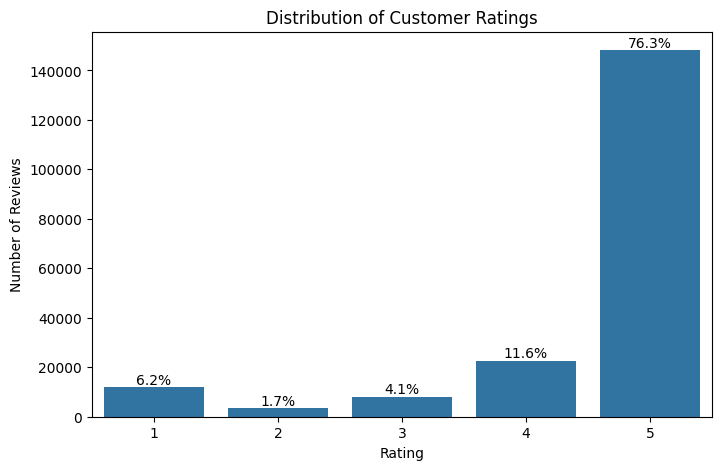

In [ ]:
# size of chart in width and height
plt.figure(figsize=(8, 5))

# count plot using seaborn
ax =sns.countplot(data=df,x='ratings', order=[1, 2, 3, 4, 5])
#order=[1, 2, 3, 4, 5] -> ensures that the bars appear in natural rating order.


total = len(df)
# calculates % by each bar
for container in ax.containers:

    for bar in container:
      height = bar.get_height()
      percentage = height / total * 100

      # writes that percentage above the corresponding bar.
      ax.text(bar.get_x() + bar.get_width() / 2, height, f'{percentage:.1f}%',
            ha='center', va='bottom')

# plot title
plt.title('Distribution of Customer Ratings')
# x-axis label
plt.xlabel('Rating')
# y-axis label
plt.ylabel('Number of Reviews')

#display chart
plt.show()

# **Step 11 — Analyze reviews over time**

In [ ]:
# minimum date and maximum date
df['review_date'].min(), df['review_date'].max()

(Timestamp('2023-07-25 15:01:35'), Timestamp('2024-08-23 19:30:05'))

In [ ]:
# count of reviews for each month
df['review_month_date'] = df['review_date'].dt.to_period('M').dt.to_timestamp()

monthly_reviews = (df.groupby('review_month_date').size()
.reset_index(name='review_count'))

monthly_reviews.head()

,review_month_date,review_count
0,2023-07-01,8279
1,2023-08-01,6801
2,2023-09-01,7593
3,2023-10-01,5824
4,2023-11-01,8719


In [ ]:
# arranging review_count in descending
monthly_reviews.sort_values('review_count',ascending=False).head(5)
#The graph helps us see the pattern, while this table helps us quantify the
#highest-volume periods.

,review_month_date,review_count
10,2024-05-01,25814
12,2024-07-01,25257
9,2024-04-01,23737
13,2024-08-01,20161
11,2024-06-01,18410


Line Chart

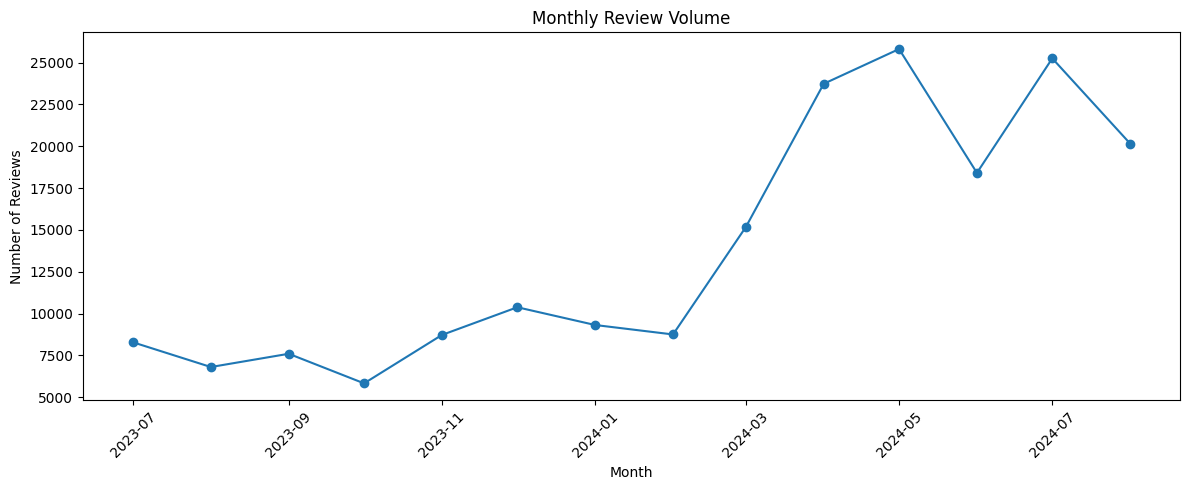

In [ ]:
#figure size
plt.figure(figsize=(12, 5))

#line chart
plt.plot(monthly_reviews['review_month_date'],monthly_reviews['review_count'],
    marker='o')

# chart title
plt.title('Monthly Review Volume')
# x=axis label
plt.xlabel('Month')
# y-axis label
plt.ylabel('Number of Reviews')

# x-axis name rotate to 45 degree
plt.xticks(rotation=45)
# tight layout
plt.tight_layout()

# display chart
plt.show()

# **Text Preprocessing and Sentiment Analysis**

# **Step 12 — Text Cleaning: Lowercasing and Punctuation Removal**

In [ ]:
import string

def clean_text(text):
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation
    text = ''.join([char for char in text if char not in string.punctuation])
    return text

df['cleaned_review'] = df['review'].apply(clean_text)

# Display a comparison of original and cleaned reviews
display(df[['review', 'cleaned_review']].head())

,review,cleaned_review
0,good,good
1,good,good
2,nice app,nice app
3,"nice, ig",nice ig
4,"this is a great app, the bot is so accurate to...",this is a great app the bot is so accurate to ...


# **Step 13 — Text Cleaning: Stop Word Removal**

In [ ]:
# Import NLTK and download stop words if not already present
import nltk
from nltk.corpus import stopwords
import re

try:
    stopwords.words('english')
except LookupError:
    nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
    # Split the text into words
    words = text.split()
    # Remove stop words
    filtered_words = [word for word in words if word not in stop_words]
    # Join the words back into a string
    return ' '.join(filtered_words)

df['processed_review'] = df['cleaned_review'].apply(remove_stopwords)

# Display a comparison of original, cleaned, and processed reviews
display(df[['review', 'cleaned_review', 'processed_review']].head())

,review,cleaned_review,processed_review
0,good,good,good
1,good,good,good
2,nice app,nice app,nice app
3,"nice, ig",nice ig,nice ig
4,"this is a great app, the bot is so accurate to...",this is a great app the bot is so accurate to ...,great app bot accurate anything gives tips gam...


# **Step 14 — Calculate Sentiment Polarity and Subjectivity**

In [ ]:
# Install TextBlob library
!pip install textblob -q

In [ ]:
from textblob import TextBlob

# Function to get sentiment polarity
def get_polarity(text):
    # Ensure text is not NaN before processing
    if pd.isna(text):
        return 0.0 # Assign a neutral polarity for NaN values
    return TextBlob(text).sentiment.polarity

# Function to get sentiment subjectivity
def get_subjectivity(text):
    # Ensure text is not NaN before processing
    if pd.isna(text):
        return 0.0 # Assign a neutral subjectivity for NaN values
    return TextBlob(text).sentiment.subjectivity

# Apply the functions to create new columns using 'processed_review'
df['polarity'] = df['processed_review'].apply(get_polarity)
df['subjectivity'] = df['processed_review'].apply(get_subjectivity)

# Display the first few rows with new sentiment scores
display(df[['processed_review', 'polarity', 'subjectivity']].head())

,processed_review,polarity,subjectivity
0,good,0.700000,0.600000
1,good,0.700000,0.600000
2,nice app,0.600000,1.000000
3,nice ig,0.600000,1.000000
4,great app bot accurate anything gives tips gam...,0.385714,0.549084


# **Step 15 — Classify Reviews into Positive, Neutral, or Negative**

In [ ]:
def classify_sentiment(polarity):
    if polarity > 0:
        return 'Positive'
    elif polarity < 0:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment'] = df['polarity'].apply(classify_sentiment)

# Display the count of each sentiment category
display(df['sentiment'].value_counts())

,count
sentiment,
Positive,142083
Neutral,44437
Negative,7684


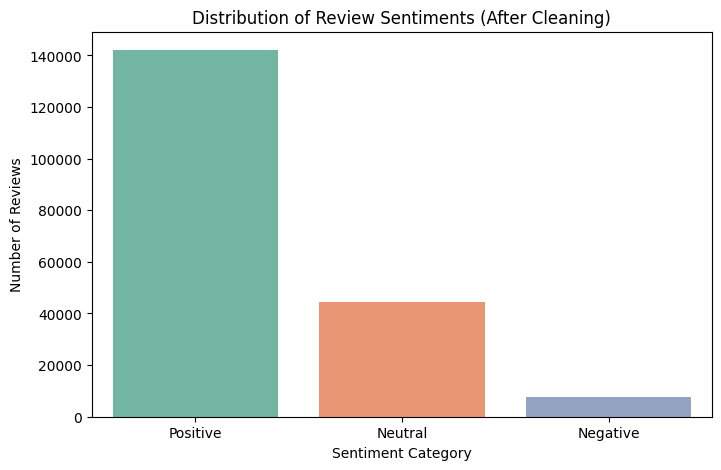

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sentiment', order=['Positive', 'Neutral', 'Negative'],
              hue ='sentiment', palette='Set2')
plt.title('Distribution of Review Sentiments (After Cleaning)')
plt.xlabel('Sentiment Category')
plt.ylabel('Number of Reviews')
plt.show()

# **Step 16 — Sentiment vs Rating**

In [ ]:
# matrix with ratings in rows and sentiments in columns
sentiment_rating = pd.crosstab(df['ratings'],df['sentiment'])

display(sentiment_rating)

sentiment,Negative,Neutral,Positive
ratings,,,
1,3264,4894,3805
2,625,1041,1680
3,771,2158,5116
4,857,4696,17050
5,2167,31648,114432


# **Step 17 — Sentiment Percentage Within Each Rating**

In [ ]:
# percentage matrix
sentiment_rating_pct = pd.crosstab(df['ratings'],df['sentiment'],
                       normalize='index').mul(100).round(2)

display(sentiment_rating_pct)

sentiment,Negative,Neutral,Positive
ratings,,,
1,27.28,40.91,31.81
2,18.68,31.11,50.21
3,9.58,26.82,63.59
4,3.79,20.78,75.43
5,1.46,21.35,77.19


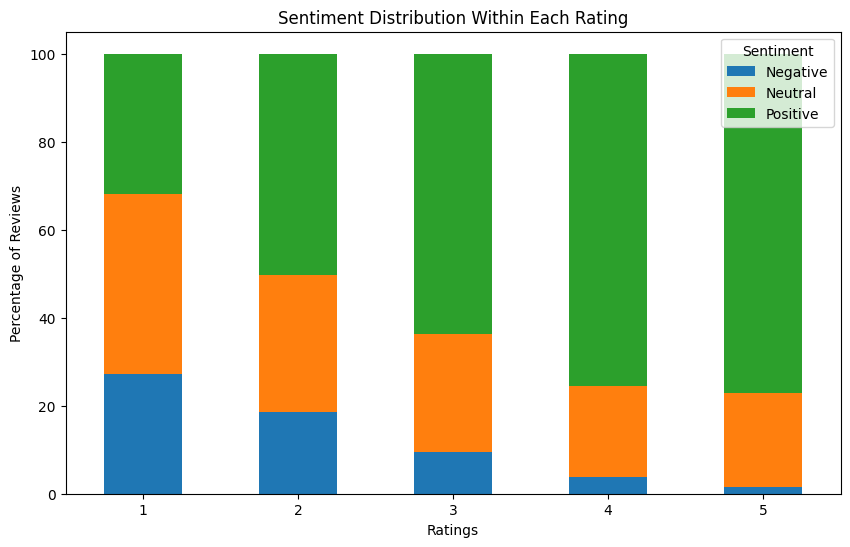

In [ ]:
# 100% stacked bar chart
sentiment_rating_pct.plot(kind='bar',stacked=True,figsize=(10, 6))

plt.title('Sentiment Distribution Within Each Rating')
plt.xlabel('Ratings')
plt.ylabel('Percentage of Reviews')
plt.legend(title='Sentiment')
plt.xticks(rotation=0)
plt.show()

# **Step 18 — Negative Review Analysis**

In [ ]:
# negative reviews
negative_reviews = df[df['sentiment'] == 'Negative'].copy()

print("Number of negative reviews:", len(negative_reviews))

Number of negative reviews: 7684


In [ ]:
# updated count of negative reviews for each ratings
negative_reviews['ratings'].value_counts().sort_index()

,count
ratings,
1,3264
2,625
3,771
4,857
5,2167


In [ ]:
# average of negative ratings
negative_reviews['ratings'].mean()

np.float64(2.7446642373763663)

In [ ]:
# display of negative reviews, ratings, polarity and subjectivity
display(negative_reviews[['review', 'ratings', 'polarity', 'subjectivity']]
        .head(20))

,review,ratings,polarity,subjectivity
134,Too expensive,1,-0.500000,0.700000
176,"Correct answer Accuracy 10 %,always provide wr...",1,-0.500000,0.900000
222,"I get a ""something went wrong"" error so I can'...",1,-0.500000,0.900000
229,"there are typing bug. if I backspace, previous...",4,-0.166667,0.166667
243,These new voices SUCK. Cove was so good and no...,3,-0.040404,0.489394
262,So so bad not working on camera,1,-0.700000,0.666667
303,This is not nice app I hate it 😡,1,-0.100000,0.950000
313,chat gpt is helpful sometimes but there's some...,1,-0.450000,0.650000
328,"They have a limit now to talk to the ai? The ""...",1,-0.200000,0.466667
378,I failed my math homework :/,1,-0.500000,0.300000


"During validation, I found some cases where the TextBlob sentiment classification did not match the apparent meaning of the review. This highlights a limitation of lexicon-based sentiment analysis, particularly for unusual phrasing, context, and ambiguous words."  ex. "unbelievable nice", "not bad", "This app is insane!"

In [ ]:
# top 20 most strong negative reviews
most_negative = negative_reviews.sort_values(by='polarity',ascending=True)

display(most_negative[['review', 'ratings', 'polarity', 'subjectivity']]
        .head(20))

,review,ratings,polarity,subjectivity
146680,HORRIBLE IT WON'T EVEN LET ME!!!!!😤😤😤🤬🤬🤬😡😡😡😠😠😠😭😭,1,-1.0,1.0
126407,WORST APP EVER.I USE THE VOICE THINGY TO GIVE ...,1,-1.0,1.0
126399,"Why it is apologizing for evey query, for ever...",3,-1.0,1.0
106755,this app is more boring from google.,3,-1.0,1.0
106586,it is the worst bot app I have ever seen 😔😔,1,-1.0,1.0
175958,Insane,5,-1.0,1.0
175951,actually insane,5,-1.0,1.0
65777,Insane!,5,-1.0,1.0
38561,this is insane,5,-1.0,1.0
79468,insane,5,-1.0,1.0


# **Step 19 — Extract Meaningful Negative Keywords**

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Remove words with length less than 3
reviews = negative_reviews['processed_review'].dropna()

# Create bigram and trigram phrases
phrases = []

for review in reviews:
    words = [word for word in review.split() if len(word) >= 3]

    # Add bigrams and trigrams
    for i in range(len(words)):
        if i + 1 < len(words):
            phrases.append(' '.join(words[i:i+2]))   # Bigram

        if i + 2 < len(words):
            phrases.append(' '.join(words[i:i+3]))   # Trigram

# Count all phrases together
phrase_counts = Counter(phrases)

# Top 20 phrases
top_phrases = phrase_counts.most_common(20)

meaningful_negative_phrase_freq = pd.DataFrame(top_phrases,
                                    columns=['word', 'frequency'])
meaningful_negative_phrase_freq


,word,frequency
0,chat gpt,206
1,worst app,130
2,wrong answer,125
3,bad app,119
4,gives wrong,116
5,wrong answers,113
6,cant even,100
7,game changer,98
8,wrong information,95
9,artificial intelligence,85


Bar Chart

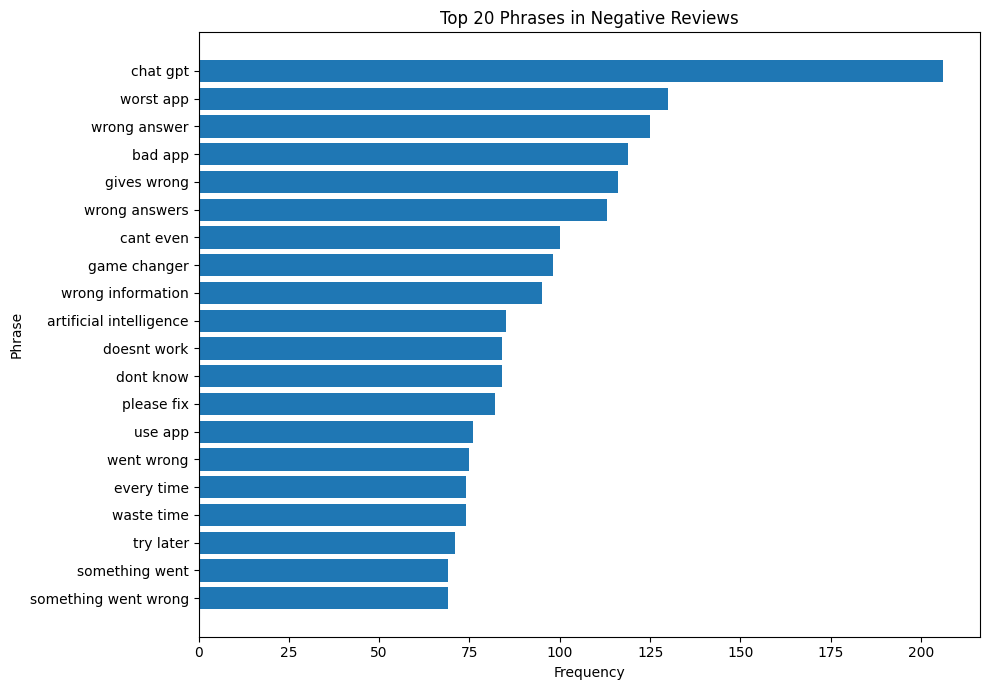

In [ ]:
# Prepare data for visualization
phrases = [phrase for phrase, count in top_phrases]
counts = [count for phrase, count in top_phrases]

# Bar chart
plt.figure(figsize=(10, 7))
plt.barh(phrases[::-1], counts[::-1])
plt.xlabel('Frequency')
plt.ylabel('Phrase')
plt.title('Top 20 Phrases in Negative Reviews')
plt.tight_layout()
plt.show()




Word Cloud

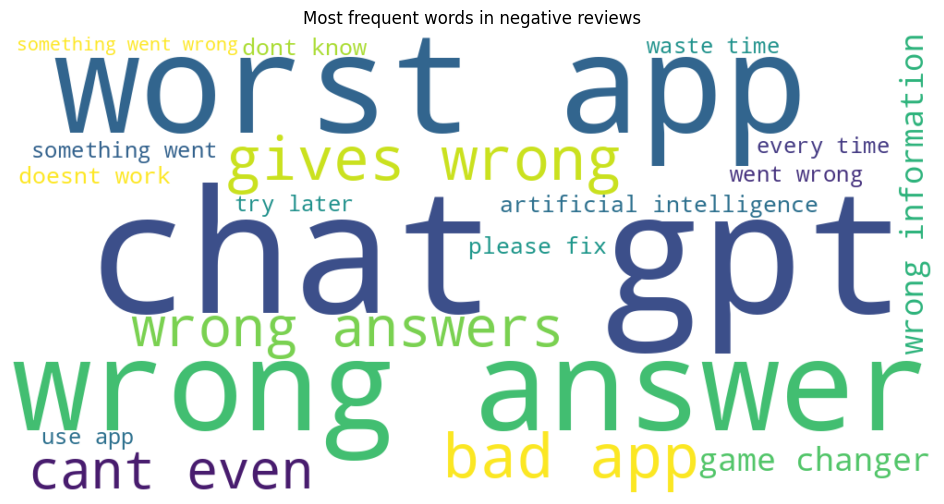

In [ ]:
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white').generate_from_frequencies(meaningful_negative_phrase_freq.
                                    set_index('word')['frequency'].to_dict())

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most frequent words in negative reviews')
plt.show()

# **Step 20 — Positive Review Analysis**

In [ ]:
# positive reviews
positive_reviews = df[df['sentiment'] == 'Positive'].copy()

print("Number of positive reviews:", len(positive_reviews))

Number of positive reviews: 142083


In [ ]:
# count of positive review for each ratings
positive_reviews['ratings'].value_counts().sort_index()

,count
ratings,
1,3805
2,1680
3,5116
4,17050
5,114432


In [ ]:
# average of positive ratings
positive_avg_rating = positive_reviews['ratings'].mean()

print("Average rating of positive reviews:", round(positive_avg_rating, 2))

Average rating of positive reviews: 4.67


# **Step 21 — Extract Meaningful Positive Keywords**

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Remove words with length less than 3
reviews = positive_reviews['processed_review'].dropna()

# Create bigram and trigram phrases
phrases = []

for review in reviews:
    words = [word for word in review.split() if len(word) >= 3]

    # Add bigrams and trigrams
    for i in range(len(words)):
        if i + 1 < len(words):
            phrases.append(' '.join(words[i:i+2]))   # Bigram

        if i + 2 < len(words):
            phrases.append(' '.join(words[i:i+3]))   # Trigram

# Count all phrases together
phrase_counts = Counter(phrases)

# Top 20 phrases
top_positive_phrases = phrase_counts.most_common(20)

meaningful_positive_phrase_freq = pd.DataFrame(top_positive_phrases,
                                    columns=['word', 'frequency'])
meaningful_positive_phrase_freq


,word,frequency
0,good app,5742
1,best app,5286
2,nice app,3215
3,great app,3026
4,chat gpt,2450
5,love app,1727
6,app ever,1540
7,amazing app,1481
8,best app ever,1199
9,really good,1153


Bar Chart

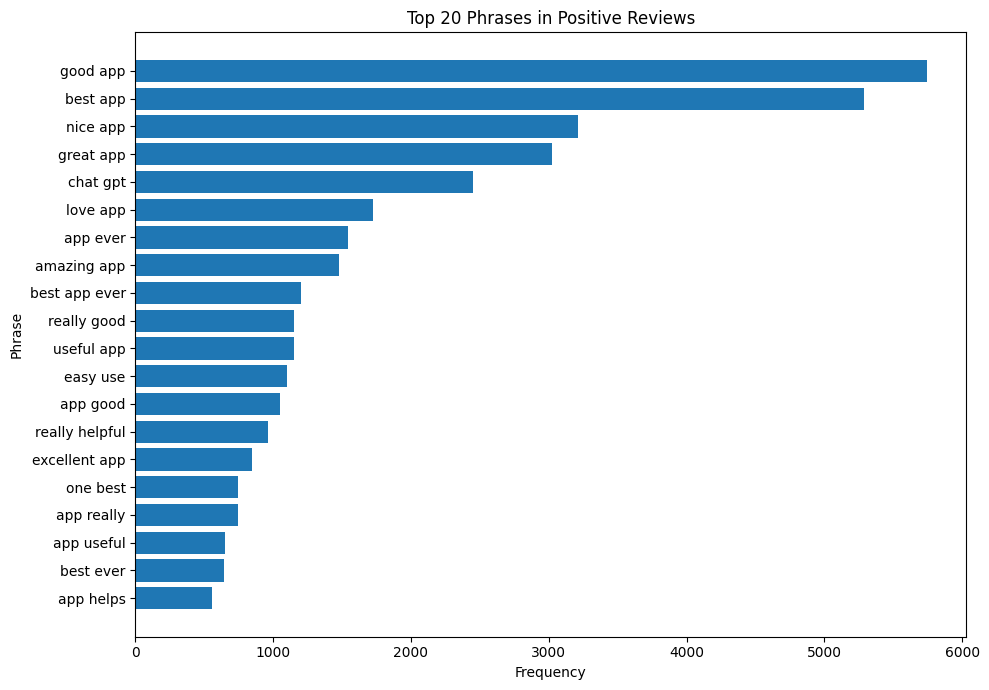

In [ ]:
# Prepare data for visualization
phrases = [phrase for phrase, count in top_positive_phrases]
counts = [count for phrase, count in top_positive_phrases]

# Bar chart
plt.figure(figsize=(10, 7))
plt.barh(phrases[::-1], counts[::-1])
plt.xlabel('Frequency')
plt.ylabel('Phrase')
plt.title('Top 20 Phrases in Positive Reviews')
plt.tight_layout()
plt.show()




Positive Word Cloud

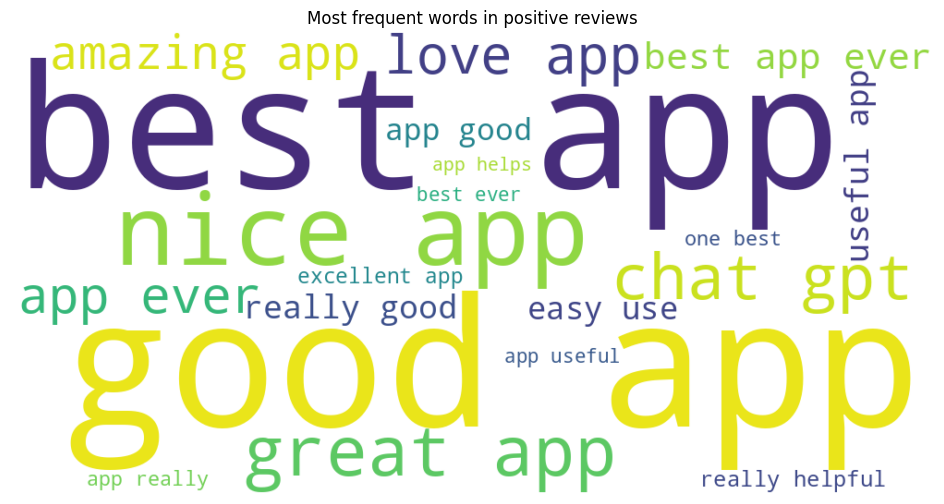

In [ ]:
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white').generate_from_frequencies(meaningful_positive_phrase_freq.
                                    set_index('word')['frequency'].to_dict())

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most frequent words in positive reviews')
plt.show()

# **Step 22 — Neutral Review Analysis**

In [ ]:
# neutral reviews
neutral_reviews = df[df['sentiment'] == 'Neutral'].copy()

print("Number of neutral reviews:", len(neutral_reviews))

Number of neutral reviews: 44437


In [ ]:
# count of neutral reviews for each ratings
neutral_reviews['ratings'].value_counts().sort_index()

,count
ratings,
1,4894
2,1041
3,2158
4,4696
5,31648


In [ ]:
# average of neutral ratings
neutral_avg_rating = neutral_reviews['ratings'].mean()

print("Average rating of neutral reviews:", round(neutral_avg_rating, 2))

Average rating of neutral reviews: 4.29


In [ ]:
# display of neutral reviews, ratings, polarity and subjectivity
display(neutral_reviews[['review', 'ratings', 'polarity', 'subjectivity']]
        .head(20))

,review,ratings,polarity,subjectivity
17,🫶🏻,5,0.0,0.0
22,beleza,5,0.0,0.0
24,abdul baset,5,0.0,0.0
25,2024-08-23 Call function doesn't get language ...,2,0.0,0.6
29,👍👍👍👍👍👍👍,5,0.0,0.0
30,Very information,5,0.0,0.0
31,It's not working after some days!,3,0.0,0.0
35,👍,5,0.0,0.0
40,অসাধারণ,5,0.0,0.0
43,This ap,5,0.0,0.0


# **Step 23 — Extract Meaningful Neutral Keywords**

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Remove words with length less than 3
reviews = neutral_reviews['processed_review'].dropna()

# Create bigram and trigram phrases
phrases = []

for review in reviews:
    words = [word for word in review.split() if len(word) >= 3]

    # Add bigrams and trigrams
    for i in range(len(words)):
        if i + 1 < len(words):
            phrases.append(' '.join(words[i:i+2]))   # Bigram

        if i + 2 < len(words):
            phrases.append(' '.join(words[i:i+3]))   # Trigram

# Count all phrases together
phrase_counts = Counter(phrases)

# Top 20 phrases
top_neutral_phrases = phrase_counts.most_common(20)

meaningful_neutral_phrase_freq = pd.DataFrame(top_neutral_phrases,
                                    columns=['word', 'frequency'])
meaningful_neutral_phrase_freq

,word,frequency
0,chat gpt,594
1,helpful app,540
2,app helpful,238
3,like app,229
4,mind blowing,226
5,helps lot,219
6,doesnt work,214
7,helpful students,164
8,try later,135
9,dont know,120


### Bar Chart

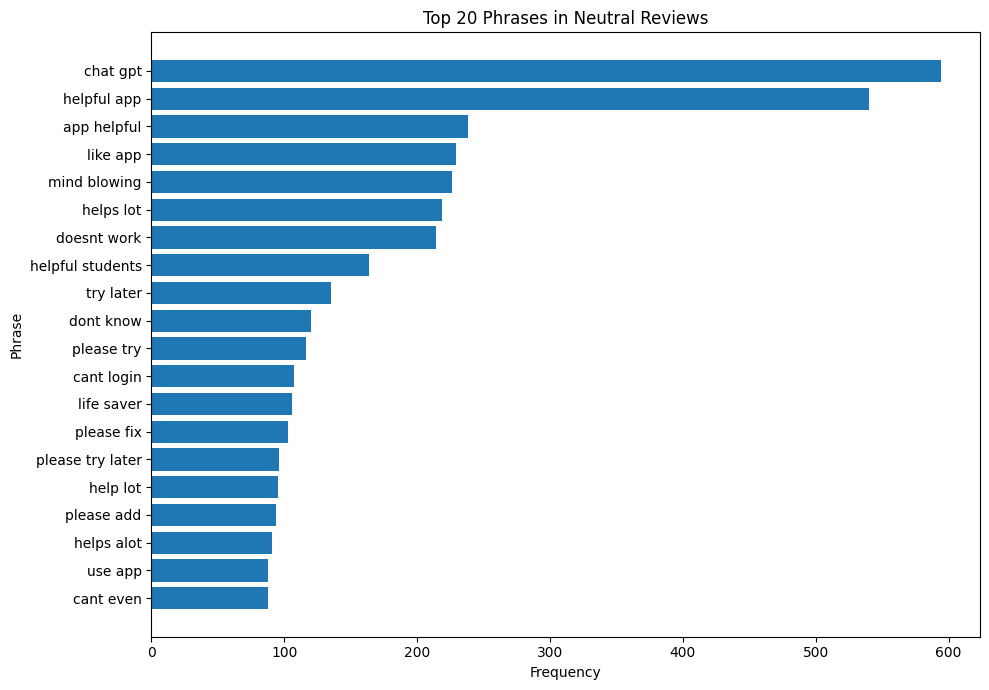

In [ ]:
# Prepare data for visualization
phrases = [phrase for phrase, count in top_neutral_phrases]
counts = [count for phrase, count in top_neutral_phrases]

# Bar chart
plt.figure(figsize=(10, 7))
plt.barh(phrases[::-1], counts[::-1])
plt.xlabel('Frequency')
plt.ylabel('Phrase')
plt.title('Top 20 Phrases in Neutral Reviews')
plt.tight_layout()
plt.show()

### Word Cloud

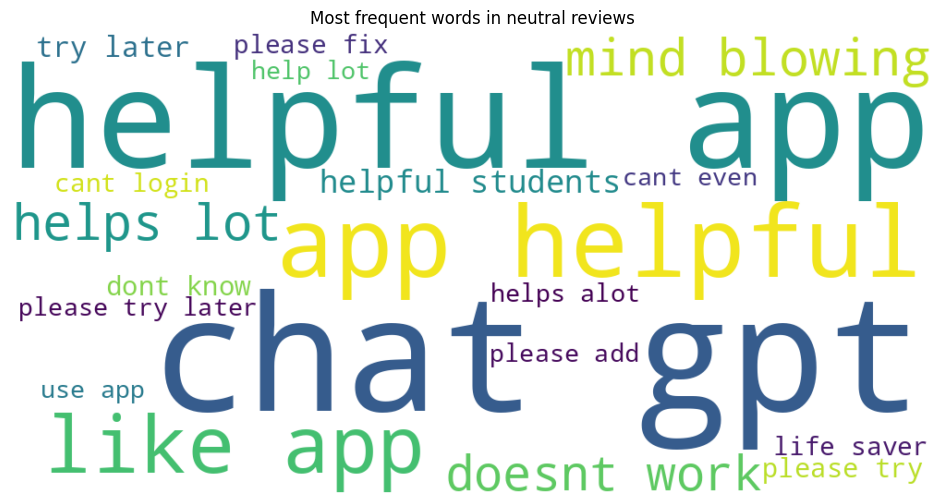

In [ ]:
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white').generate_from_frequencies(meaningful_neutral_phrase_freq.
                                    set_index('word')['frequency'].to_dict())

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most frequent words in neutral reviews')
plt.show()

# **Step 24 — Issue Identification**

# For Negative Keywords

In [ ]:
# Categorize negative phrases into issue themes

negative_theme_mapping = {
    'Answer Accuracy / Information Quality': ['wrong answer','gives wrong',
                                          'wrong answers','wrong information'],

    'App Functionality / Performance': ['worst app','bad app','doesnt work',
        'went wrong','something went','something went wrong'],

    'Troubleshooting / Fix Requests': ['please fix','try later'],

    'Usage / User Experience': ['cant even','use app','every time','waste time'],

    'General / Ambiguous': ['chat gpt','game changer','artificial intelligence',
        'dont know']}

# Create theme-frequency dictionary
negative_theme_freq = {}

for theme, phrases in negative_theme_mapping.items():
    frequency = meaningful_negative_phrase_freq[
        meaningful_negative_phrase_freq['word'].isin(phrases)]['frequency'].sum()

    negative_theme_freq[theme] = frequency

# Convert to DataFrame
negative_theme_df = pd.DataFrame(negative_theme_freq.items(),
                    columns=['theme', 'frequency']).sort_values(
                        'frequency', ascending=False)

negative_theme_df

,theme,frequency
1,App Functionality / Performance,546
4,General / Ambiguous,473
0,Answer Accuracy / Information Quality,449
3,Usage / User Experience,324
2,Troubleshooting / Fix Requests,153


Bar Chart

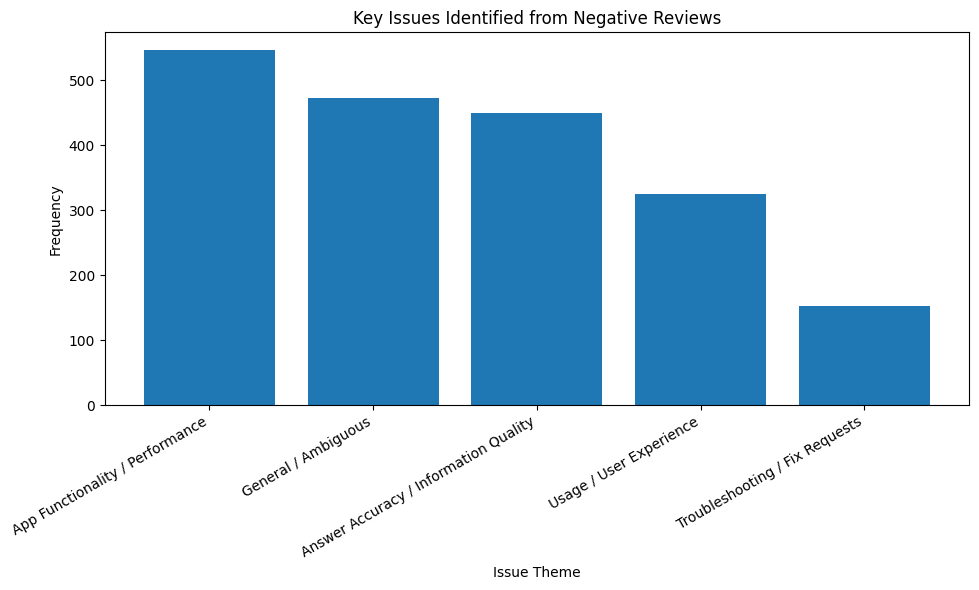

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    negative_theme_df['theme'],
    negative_theme_df['frequency']
)

plt.xlabel('Issue Theme')
plt.ylabel('Frequency')
plt.title('Key Issues Identified from Negative Reviews')

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# For Neutral Keywords

In [ ]:
# Categorize neutral phrases into themes

neutral_theme_mapping = {
    'Helpfulness / Utility': ['helpful app','app helpful','helps lot',
        'helpful students','help lot','helps alot','life saver'],

    'App Usage / Experience': ['like app','mind blowing','use app'],

    'Functionality / Access Issues': ['doesnt work','cant login','cant even'],

    'Troubleshooting / Retry': ['try later','please try','please fix',
                                'please try later'],

    'Feature Requests': ['please add'],

    'General / Ambiguous': ['chat gpt','dont know']}

# Create theme-frequency dictionary
neutral_theme_freq = {}

for theme, phrases in neutral_theme_mapping.items():
    frequency = meaningful_neutral_phrase_freq[
        meaningful_neutral_phrase_freq['word'].isin(phrases)
    ]['frequency'].sum()

    neutral_theme_freq[theme] = frequency

# Convert to DataFrame
neutral_theme_df = pd.DataFrame(
    neutral_theme_freq.items(),
    columns=['theme', 'frequency']
).sort_values('frequency', ascending=False)

neutral_theme_df

,theme,frequency
0,Helpfulness / Utility,1453
5,General / Ambiguous,714
1,App Usage / Experience,543
3,Troubleshooting / Retry,450
2,Functionality / Access Issues,409
4,Feature Requests,94


Bar Chart

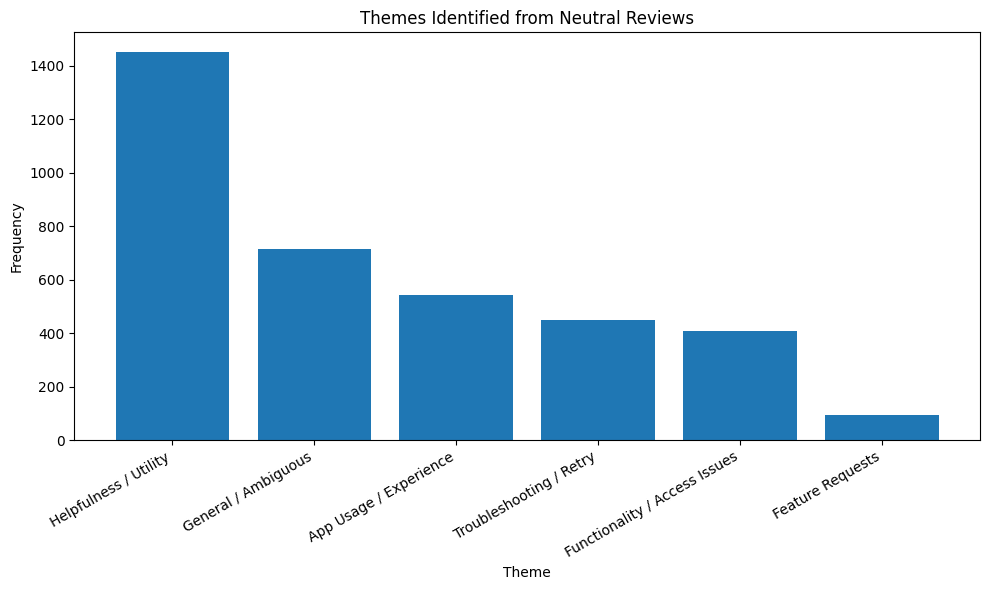

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(neutral_theme_df['theme'],neutral_theme_df['frequency'])

plt.xlabel('Theme')
plt.ylabel('Frequency')
plt.title('Themes Identified from Neutral Reviews')

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# **Step 25 — Monthly Positive vs Negative Sentiment Trend**

In [ ]:
#"Group reviews by month → then convert those monthly labels into real dates so
#we can analyze and plot the time series properly."
monthly_sentiment = (df.groupby([df['review_date'].dt.to_period('M'),
        'sentiment']).size().unstack(fill_value=0))
#"Convert the monthly PeriodIndex into datetime values and assign them back as the index."
monthly_sentiment.index = monthly_sentiment.index.to_timestamp()

display(monthly_sentiment)

sentiment,Negative,Neutral,Positive
review_date,,,
2023-07-01,447,1976,5856
2023-08-01,418,1578,4805
2023-09-01,369,1671,5553
2023-10-01,233,1331,4260
2023-11-01,376,1955,6388
2023-12-01,456,2354,7565
2024-01-01,453,2210,6650
2024-02-01,439,2013,6296
2024-03-01,621,3544,11008


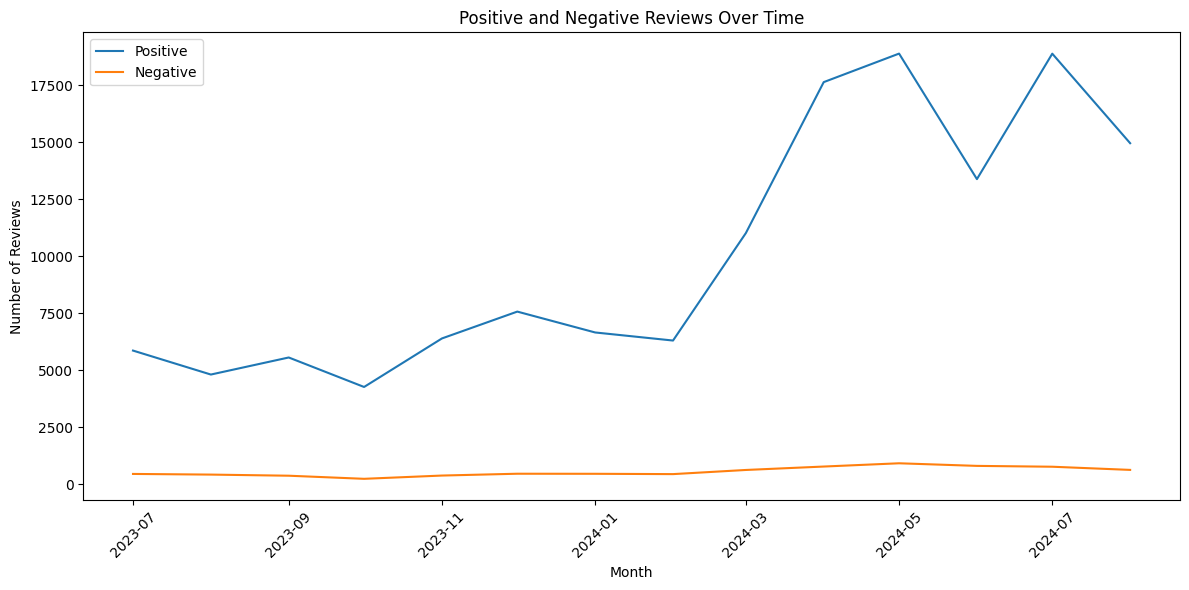

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_sentiment.index,monthly_sentiment['Positive'],label='Positive')

plt.plot(monthly_sentiment.index,monthly_sentiment['Negative'],label='Negative')

plt.title('Positive and Negative Reviews Over Time')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Step 26 — Overall Sentiment Summary**

In [ ]:
# count of reviews by sentiments
sentiment_summary = (df['sentiment'].value_counts().rename_axis('sentiment')
    .reset_index(name='review_count'))

# percentage of review by sentiments
sentiment_summary['percentage'] = (sentiment_summary['review_count']/
                                   len(df) * 100).round(2)

display(sentiment_summary)

,sentiment,review_count,percentage
0,Positive,142083,73.16
1,Neutral,44437,22.88
2,Negative,7684,3.96


Rating vs Sentiment Summary

In [ ]:
# count of reviw and average of ratings by sentiments
sentiment_rating_summary = (df.groupby('sentiment')['ratings'].agg(['count', 'mean'])
      .round(2).sort_values('mean', ascending=False))

display(sentiment_rating_summary)

,count,mean
sentiment,,
Positive,142083,4.67
Neutral,44437,4.29
Negative,7684,2.74


Highest and Lowest Negative-Sentiment Months

In [ ]:
monthly_sentiment['Total'] = monthly_sentiment['Negative']+ monthly_sentiment['Neutral'] + monthly_sentiment['Positive']
monthly_sentiment['Negative_%'] = (monthly_sentiment['Negative'] /
                                   monthly_sentiment['Total']) * 100
monthly_sentiment['Positive_%'] = (monthly_sentiment['Positive'] /
                                   monthly_sentiment['Total']) * 100

# highest negative review months
highest_negative_month = monthly_sentiment['Negative_%'].idxmax()
# lowest negative review months
lowest_negative_month = monthly_sentiment['Negative_%'].idxmin()

print("Highest negative sentiment:",highest_negative_month.strftime('%B %Y'),
    "-",monthly_sentiment.loc[highest_negative_month, 'Negative_%'],"%")

print("Lowest negative sentiment:",lowest_negative_month.strftime('%B %Y'),"-",
    monthly_sentiment.loc[lowest_negative_month, 'Negative_%'],"%")

Highest negative sentiment: August 2023 - 6.146154977209234 %
Lowest negative sentiment: July 2024 - 3.02094468860118 %


Most Positive Month

In [ ]:
# highest positive month
highest_positive_month = monthly_sentiment['Positive_%'].idxmax()

print("Highest positive sentiment:",highest_positive_month.strftime('%B %Y'),
"-",monthly_sentiment.loc[highest_positive_month, 'Positive_%'],"%")

Highest positive sentiment: July 2024 - 74.72779823415291 %


# **Step 27 — Final NLP Insights**

**1. Overall sentiment distribution**

73.16% of reviews were classified as Positive, making it the largest sentiment category.

22.88% were classified as Neutral, while only 3.96% were classified as Negative.

So, based on the TextBlob classification, positive language dominates the review dataset.

**2. Sentiment and rating show a clear relationship**

Average Positive rating → 4.67
Average Neutral rating → 4.29
Average Negative rating → 2.74

This supports the idea that the sentiment analysis is capturing a meaningful portion of the overall tone in the reviews.

**3. Time-series finding**

Highest negative sentiment: August 2023 — 6.15%
Lowest negative sentiment: July 2024 — 3.02%
Highest positive sentiment: July 2024 — 74.73%

The monthly percentages show that the proportion of positive and negative classifications changed over time, while the positive category remained substantially larger throughout the observed period.

**4. Important NLP limitation**

We also found rating–sentiment mismatches.

For example, some 5-star reviews were classified as Negative, while some 1-star reviews were classified as Positive. Examples such as "insane" receiving negative polarity demonstrate the limitation of TextBlob's lexicon-based approach when dealing with context, slang, negation, sarcasm, and ambiguous expressions.

Therefore, the sentiment results should be treated as analytical signals rather than perfect ground truth.

# **Step 28 — Business Recommendations**

**1 — Monitor Negative Review**s

A business could create a recurring monitoring process for:

negative sentiment percentage
low-rated reviews
sudden increases in negative reviews
recurring complaint language

**2 — Investigate Accuracy-Related Complaints**

Words such as:
wrong, answer, information appear frequently among the negative reviews.
Instead of immediately concluding that the system has an accuracy problem, the product team should investigate these reviews further and categorize them by issue type.

**3 — Monitor Technical Issues**

Words such as:
error, login, slow, fix can indicate potential technical or usability concerns.
These reviews could be combined with technical/app data such as:

crash logs, response times, login failure rates, app versions, support tickets, etc

That would allow the company to compare user complaints with actual system metrics.

**4 — Improve Sentiment Classification**

For a production-level system, the business could move beyond TextBlob and evaluate more advanced NLP models.

For example:
TextBlob → baseline

then potentially:
TF-IDF + Machine Learning or more advanced transformer-based approaches.
The model should ideally be evaluated against a manually labeled sample using metrics such as:

Accuracy

Precision

Recall

F1-score

This would tell us how well the sentiment model actually performs.

**Overall, the project demonstrates how Python, Pandas, visualization, and NLP techniques can be combined to transform large volumes of unstructured customer reviews into meaningful analytical insights and business recommendations.**